# What's Involved in Fine-Tuning?

* Find an appropriate pretrained ("foundation" or "base") model, based on training data and size (#parameters)
* Curate a targeted, application-oriented dataset
* Continue training as with pretraining. This is very similar to "transfer learning" (e.g. vision models)
* Adjust params, e.g. smaller learning rate, freezing some layers
* Test, adjust, iterate

# What does "fine-tuning" mean?

* Fine-tuning means making targeted adjustments to an existing pretrained model. It takes days or weeks instead of months, and has much smaller computational requirements
* There are myriad choices in fine-tuning; the challenge is from knowing what you want to do with the model.

# Fine-Tune a Pretrained GPT2

* Some shortcuts and tricks
* Fine-tuning is actually same thing as pretraining
* How to set params for fine-tuning
* How to eval the effectiveness of fine-tuning

# Goals

1. Import and tokenize Gulliver's Travels
2. Find the 100 most common tokens
3. Count common-token occurences in generated text
4. Fine-tune the model (with internal loss calculations)
5. Consider several evaluations

# Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import requests

import torch
import torch.nn as nn
import torch.nn.functional as F

from transformers import AutoModelForCausalLM, GPT2Tokenizer
import requests

# vector plots
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

In [2]:
# load pretrained GPT-2 model and tokenizer
gpt2      = AutoModelForCausalLM.from_pretrained('gpt2')
tokenizer = GPT2Tokenizer.from_pretrained('gpt2')

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

In [3]:
# hyperparameters
seq_len = 256
batch_size = 16

# use GPU
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

# Download

In [4]:
# tokenize the text
# Gulliver's travels
text = requests.get('https://www.gutenberg.org/cache/epub/829/pg829.txt').text

# old way
gt_tokens = torch.tensor(tokenizer.encode(text), dtype = torch.long)
print(gt_tokens.shape)

# better way
gt_tokens = tokenizer.encode(text, return_tensors='pt')
print(gt_tokens.shape)

# but the rest of the code is setup for dimensionless tensors
gt_tokens = gt_tokens[0]
print(gt_tokens.shape)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (158340 > 1024). Running this sequence through the model will result in indexing errors


torch.Size([158340])
torch.Size([1, 158340])
torch.Size([158340])


# 100 Most Frequent Tokens in Gulliver's Travel

In [5]:
# find the most frequent 100 tokens
uniq, counts = np.unique(gt_tokens, return_counts=True)
freq_idx = np.argsort(counts)[::-1]
top_100 = uniq[freq_idx[:100]]

for t in top_100:
    print(
        f'Token {t:5} appears {torch.sum(gt_tokens == t):4} times '
        f'and is "{tokenizer.decode([t])}"'
    )

Token    11 appears 10060 times and is ","
Token   198 appears 9923 times and is "
"
"
Token   262 appears 5393 times and is " the"
Token   286 appears 3779 times and is " of"
Token   290 appears 3468 times and is " and"
Token   284 appears 3356 times and is " to"
Token    13 appears 3006 times and is "."
Token   314 appears 2657 times and is " I"
Token   257 appears 2431 times and is " a"
Token   287 appears 1900 times and is " in"
Token    26 appears 1562 times and is ";"
Token   616 appears 1474 times and is " my"
Token   373 appears 1199 times and is " was"
Token   326 appears 1061 times and is " that"
Token   502 appears  964 times and is " me"
Token   351 appears  941 times and is " with"
Token   355 appears  920 times and is " as"
Token   465 appears  823 times and is " his"
Token   416 appears  794 times and is " by"
Token   329 appears  776 times and is " for"
Token   543 appears  774 times and is " which"
Token   447 appears  734 times and is "�"
Token   340 appears  718 time

In [6]:
# move the model to the GPU
gpt2 = gpt2.to(device)

In [7]:
# check out some text
prompt = 'I cannot believe that'
in2gpt = tokenizer.encode(prompt, return_tensors='pt').to(device)

output = gpt2.generate(in2gpt,
                       max_length = 100,
                       pad_token_id=50256,
                       do_sample=True).cpu()

print(tokenizer.decode(output[0]))

I cannot believe that someone is such a good-hearted guy, or that he should have the courage to say 'no' to something I'm really trying to do. What does it say about you to be so kind to someone you didn't take a chance on and that's what drives you to make your own choices? I really want to know what your options are when doing this thing, and to be able to do things with them when they're not working for you. I can't tell


# Quantify the Freq of GT Frequent tokens in GPT's output

In [8]:
num_reps = 10 # number of random reps
num_toks = 100 # output length

# random starting tokens
rand_starts = torch.randint(tokenizer.vocab_size, (num_reps,1)).to(device)
tokenizer.decode(rand_starts)

[' condemnation',
 'CO',
 ' goes',
 ' detractors',
 'ol',
 ' federally',
 ' ever',
 ' collaborating',
 ' Schwarzenegger',
 '�']

In [9]:
# generate some data
out = gpt2.generate(
    rand_starts,
    max_length = num_toks + 1,
    min_length = num_toks + 1,
    do_sample = True,
    bad_words_ids = [tokenizer.encode(tokenizer.eos_token)],
    pad_token_id = tokenizer.encode(tokenizer.eos_token)[0]
).cpu()

print(out, '\n')

for o in out:
  print('\n*** Next batch of output:')
  print(tokenizer.decode(o))

[transformers] The attention mask is not set with a batched input, and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.


tensor([[28215,   393, 14425,  ...,   262,  1708,  2236],
        [ 8220,    38,   337,  ..., 22313,  5721,  5752],
        [ 2925,    11,   290,  ...,   612,   389,  6088],
        ...,
        [38152,   393, 34962,  ...,   262,   761,   284],
        [47507,    25,   554,  ...,   717,  1517,   345],
        [  103,   314,  3505,  ...,  2042,  3367,   553]]) 


*** Next batch of output:
 condemnation or denial of the facts and circumstances relating to the events of that day, or as a result is made of in his judgment or by reference to them or to the record of the court, or by reference to the opinion of the attorney general, or by reference to other actions taken by the court.

Sec. 9. [S.2301.030-9]. (a) Upon conviction for any violation of this section, there is every possibility that one or more of the following shall

*** Next batch of output:
COG MATCH_BOUNCE = 15 ( 0 , 19 , 4 ) ; int row : int { 0 = 6, 19 = 4 ; int col_row ; 8 = 5 + 25 ; int column8 ; 4 = 7 + 25 ; int row ; 4 +

In [10]:
# calculate and report the percentage
percent_freq_tokens_pre = np.mean(100*np.isin(out[:,1:],top_100).flatten())
print(f'Gulliver\'s travels common tokens appeared in {percent_freq_tokens_pre}% of new tokens')

Gulliver's travels common tokens appeared in 47.0% of new tokens


# Fine-Tune the Model

* We pick very small learning rate. For fine-tuning we apply way smaller lr because we don't want to overwrite world model that already is created we just want to update it with some new knowledge.
* We dont use loss function because its calculated internally due to HuggingFace

In [11]:
optimizer = torch.optim.AdamW(gpt2.parameters(), lr = 5e-5, weight_decay=.01)

In [12]:
num_samples = 1234

# initialize losses
train_loss = np.zeros(num_samples)

for sample_i in range(num_samples):

  # get a batch of data
  ix = torch.randint(len(gt_tokens)-seq_len, size = (batch_size,))
  X  = gt_tokens[ix[:, None] + torch.arange(seq_len)]

  # move data to GPU
  X = X.to(device)

  # clear previous gradients
  gpt2.zero_grad()

  # forward pass (Hugging Face shifts X internally to get y)
  outputs = gpt2(X, labels=X)
  loss = outputs.loss # we do not need to have separate loss function

  # backprop
  loss.backward()
  optimizer.step()

  # store the per-sample loss
  train_loss[sample_i] = loss.item()

  # update progress display
  if sample_i%77==0:
    print(f'Sample {sample_i:4}/{num_samples}, train_loss: {train_loss[sample_i]:.4f}')

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Sample    0/1234, train_loss: 5.2225
Sample   77/1234, train_loss: 2.8717
Sample  154/1234, train_loss: 2.6921
Sample  231/1234, train_loss: 2.4411
Sample  308/1234, train_loss: 2.0671
Sample  385/1234, train_loss: 1.7532
Sample  462/1234, train_loss: 1.3688
Sample  539/1234, train_loss: 1.1539
Sample  616/1234, train_loss: 0.9362
Sample  693/1234, train_loss: 0.9302
Sample  770/1234, train_loss: 0.5876
Sample  847/1234, train_loss: 0.5142
Sample  924/1234, train_loss: 0.3303
Sample 1001/1234, train_loss: 0.2847
Sample 1078/1234, train_loss: 0.2255
Sample 1155/1234, train_loss: 0.2183
Sample 1232/1234, train_loss: 0.2079


* `gpt2(X, labels=X)` - HuggingFace automatically makes forward pass on t+1 labels. It has inside something like:

```
logits = gpt2(X).logits

predictions = logits[:, :-1, :]
targets     = X[:, 1:]

loss = cross_entropy(predictions, targets)
```

# Plot Losses

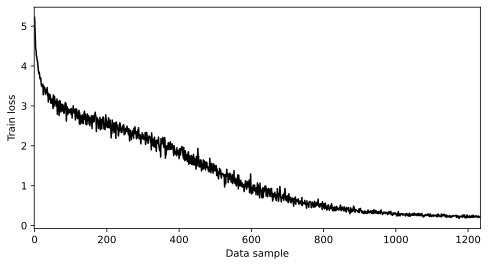

In [13]:
# plot the losses
plt.figure(figsize=(8, 4))
plt.plot(train_loss, 'k', markersize=8)

plt.gca().set(
    xlabel='Data sample',
    ylabel='Train loss',
    xlim=[-1, num_samples]
)

plt.show()

# Qual Assessment

In [14]:
# Qualitative assessment
prompt = 'I cannot believe that'

in2gpt = tokenizer.encode(
    prompt,
    return_tensors='pt'
).to(device)

output = gpt2.generate(
    in2gpt,
    max_length=100,
    pad_token_id=50256
)

print(tokenizer.decode(output[0]))

I cannot believe that I have not been
pushed farther by the horror I have been in since my landing; for it
is almost three months into a design to carry me to the kingdom
of Luggnagg by air, out of the view of the emperor and his
council, which region is said to be the mother of all other
_Yahoos_. In these abominable planes, I placed my life, and
grave my


# Calculate percentage of GT Tokens Generated

In [15]:
# random starting tokens
rand_starts = torch.randint(
    tokenizer.vocab_size,
    (num_reps, 1)
).to(device)

# generate some data
out = gpt2.generate(
    rand_starts,
    max_length=num_toks + 1,
    min_length=num_toks + 1,
    do_sample=True,
    bad_words_ids=[tokenizer.encode(tokenizer.eos_token)],
    pad_token_id=tokenizer.encode(tokenizer.eos_token)[0]
).cpu()

for o in out:
    print('\n*** Next batch of output:')
    print(tokenizer.decode(o))

# calculate and report the percentage
percent_freq_tokens_post = np.mean(
    100 * np.isin(out[:, 1:], top_100).flatten()
)

print(
    f'Common GT tokens usage went from '
    f'{percent_freq_tokens_pre:.2f}% to '
    f'{percent_freq_tokens_post:.2f}% after fine-tuning.'
)


*** Next batch of output:
SG; if a traveller had reason to believe I would
arrive late, or pick up a friend, I took leave of his wife, and all
my other possessions, put them into my box, and went on board his
co-pilot. We board-room is roof-top, but the plane is over the board- at the
end!

I have right, and must say, upon a very considerable point, whether I


*** Next batch of output:
 regex, and his favourite artist to observe the usual
form, but with much ingenuity that would not consist in copying
this invention.

His majesty desired that I might have some excuse to eat with what
vast food I had, although it were necessitated by some late
businesss; particularly after I had given way to joy, as I sat in
an inn with my wife and family, where I had no occasion of
drinking,

*** Next batch of output:
 reaction to any one of its
motives, but had yet to produce the same effect.

The female _Yahoo_, happened to be soft enough; for me and herquickShip
little cuddledudge was able to dig 